# Aprendizado Não Supervisionado

O **aprendizado não supervisionado** é uma abordagem de aprendizado de máquina em que o algoritmo recebe dados **sem rótulos**. Ou seja, o modelo não sabe previamente a resposta correta, mas busca encontrar **padrões escondidos** ou **estruturas** dentro dos dados.

Um dos principais métodos de aprendizado não supervisionado é o **agrupamento (clustering)**, que consiste em separar os dados em grupos que tenham características semelhantes.

Para definir grupos, duas situações são analisadas: <br/>
1º ) Todos os pontos de dados em um cluster devem ser semelhantes entre si <br/>
2º ) Os pontos de dados de diferentes clusters devem ser tão diferentes quanto possível

Como o volume de dados cresce dia após dia, fica fácil entender a vantagem do agrupamento para facilitar a geração de informações úteis. Por isso e por se adaptar bem a um grande número de amostras, clusterings têm sido utilizados em uma grande variedade de áreas. Suas aplicações práticas são inúmeras, por exemplo:

- Segmentação de clientes
- Agrupamento de documentos
- Mecanismos de recomendação
- Construção de grupos genéticos
- Criação de centros de distribuição logísticos
- Segmentação de imagens


## Agrupando objetos por similaridade usando o K-Médias (K-Means)

O **K-Médias (K-means)** é um dos algoritmos mais usados para agrupamento, tanto academicamente quanto na indústria. É um algoritmo fácil de implementar e também é computacionalmente eficiente comparado com outros algoritmos de agrupamento. Ele funciona da seguinte forma:

1. Define-se o número de grupos (k).
2. O algoritmo escolhe aleatoriamente k pontos como centróides iniciais.
3. Cada ponto é atribuído ao grupo cujo centróide está mais próximo.
4. Os centróides são recalculados como a média dos pontos de cada grupo.
5. O processo se repete até que os centróides não mudem mais ou o limite de iterações seja atingido.

Quando parar o algoritmo?

Existem essencialmente três critérios de interrupção:

1.  Centroides de clusters recém-formados não mudam
2.  Os pontos permanecem no mesmo cluster
3.  O número máximo de iterações for atingido

O resultado é a divisão dos dados em k grupos.

Observe o funcionamento do algoritmo nessa [simulação](https://www.naftaliharris.com/blog/visualizing-k-means-clustering/).


## Exemplo prático com K-means
Vamos aplicar o K-means em um conjunto de dados sintético para entender como ele agrupa os pontos.


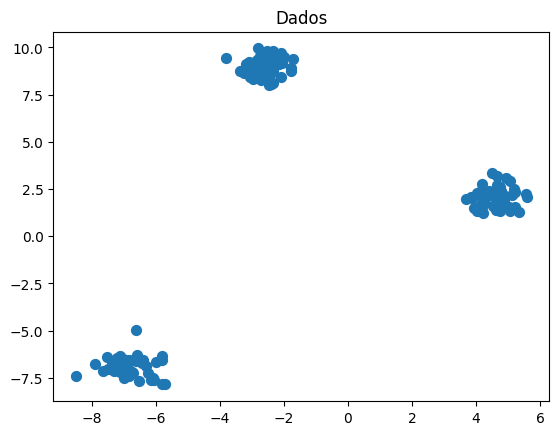

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Gerando dados sintéticos com 3 grupos
X, y_true = make_blobs(n_samples=150, centers=3, cluster_std=0.5, random_state=42)

# Visualizando os dados sem agrupamento
plt.scatter(X[:,0], X[:,1], s=50)
plt.title('Dados')
plt.show()

O dataset gerado aleatoriamente consiste de 150 amostras que visualmente já apresentam um certo tipo de agrupamento, pois foi criado aritficialemente. Como já sabemos que existem 3 grupos nesse conjunto de dados, vamos parametrizar o nosso modelo escolhendo um k=3:

In [ ]:
# Aplicando o K-means com 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42)

Agora, podemos treinar o modelo. No caso de algoritmos de agrupamento, só precisamos informar o conjunto de dados inteiro, sem fazer divisão entre treinamento e teste.
Porque disso? Reflitam...

Vamos treinar usando o método fit():

In [ ]:
kmeans.fit(X)

KMeans(n_clusters=3, random_state=42)

Esse treinamento faz com que o K-Médias ajuste os centros dos grupos. Para que nós sejamos capazes de saber onde estão esses centros e gerar previsões, usamos o preditc().

Vamos exibir o resultado do agrupamento. As cores demonstram os diferentes grupos o X marca o ponto central de cada grupo:

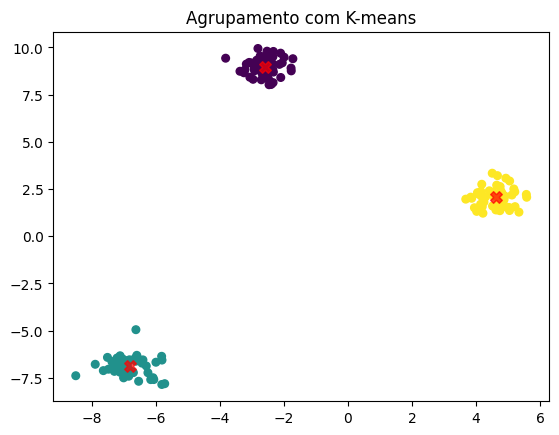

In [ ]:
y_kmeans = kmeans.predict(X)

# Visualizando os grupos encontrados
plt.scatter(X[:,0], X[:,1], c=y_kmeans, s=30, cmap='viridis')
centros = kmeans.cluster_centers_
plt.scatter(centros[:,0], centros[:,1], c='red', s=70, alpha=0.7, marker='X')
plt.title('Agrupamento com K-means')
plt.show()

**Alguns Pontos Importantes a Serem Enfatizados:**

Certos fatores podem afetar a eficácia dos clusters finais ao se usar o K-Means. Portanto, devemos ter atenção aos seguintes detalhes ao se resolver problemas utilizando este algoritmo:

- **Número de Clusters**: O número de clusters em que você deseja agrupar seus pontos influencia diretamente na qualidade do agrupamento. Existe duas formas de avaliação principais para auxílio da escolha de k, o método do cotovelo e da silhueta


- **Valores Iniciais dos Centroides**: A escolha dos centros iniciais do cluster pode ter impacto na formação final do cluster. Como a seleção inicial dos k pontos para centroide é aleatória, se esta escolha for ruim, gerará clusters ruins. Porém, existe um método para superar esta desvantagem do ajuste dos valores iniciais chamado K-Means++. Esse método garante uma inicialização mais inteligente dos centroides e melhora a qualidade do agrupamento


- **Outliers**: A formação de clusters é muito sensível à presença de outliers. Outliers puxam o cluster para si mesmo, afetando a formação ideal do cluster


- **Medidas de Distância**: O uso de diferentes medidas de distância (usadas para calcular a distância entre um ponto de dados e o centro do cluster) pode gerar diferentes clusters


- **Padronize os Dados**: Como se trata de um algoritmo de medida, seus dados devem ser numéricos, não categóricos, sendo sempre importante padroniza-los para que não fiquem em unidades de medidas muito discrepantes entre si podendo enviesar seus resultados


- **Verifique a Convergência**: Você deve sempre verificar a convergência. O processo pode não convergir em um determinado número de iterações

## Avaliando agrupamentos

Ao contrário do aprendizado supervisionado, onde temos a verdade (rótulo) para avaliar o desempenho do modelo, a análise de agrupamento não possui uma métrica de avaliação sólida que possamos usar para avaliar o resultado de diferentes algoritmos de agrupamento. Além disso, como K-Means requer k como entrada e não o aprende a partir de dados, não há uma resposta certa em termos do número de clusters que devemos assumir em cada problema. Às vezes, o conhecimento do domínio e a intuição podem ajudar, mas geralmente esse não é o caso. Na metodologia de previsão de cluster, podemos avaliar o desempenho dos modelos com base em diferentes clusters k.

Veremos duas métricas comuns para este problema:
- Método do Cotovelo
- Método da Silhueta

**Método do Cotovelo**

É um dos métodos mais famosos pelos quais você pode selecionar o valor certo de k e aumentar o desempenho do seu modelo.<br/>
Com base na soma da distância quadrada entre os pontos de dados e os centroides de seus respectivos clusters ele calcula a distância média em cada cluster e as somam. Ou seja, ele mensura a 1ª propriedade dos clusters. Como buscamos minimizar as distâncias intra cluster, e este método mede justamente a distância, fica claro que quanto menor seu valor, melhor. Este conceito também pode ser encontrado na literatura como Inércia. <br/>

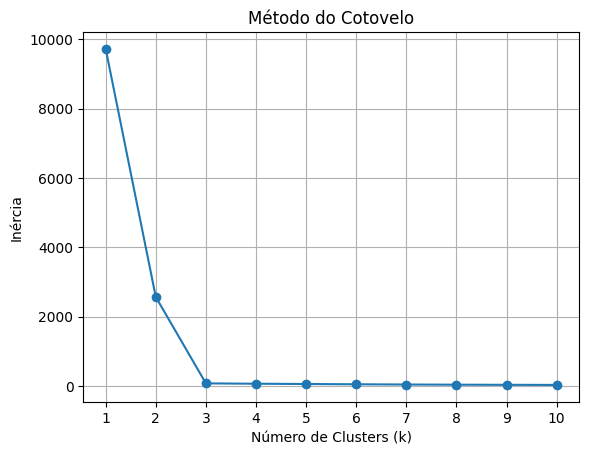

In [ ]:
inercia = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10) # Adicionado n_init para evitar warning
    kmeans.fit(X)
    inercia.append(kmeans.inertia_)

plt.plot(range(1, 11), inercia, marker='o') # Adicionado o marcador 'o'
plt.title('Método do Cotovelo')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.xticks(range(1, 11)) # Adicionado para mostrar todos os valores de k no eixo x
plt.grid(True) # Adicionado grade para melhor visualização
plt.show()

A ideia ao analisar o gráfico é perceber onde a inércia diminui. Esse ponto indica um número adequado para ser usado como valor de k.

**Método da Silhueta**

Mais barata computacionalmente que o método do cotovelo, a análise de silhueta pode ser usada para estudar a distância de separação entre os clusters resultantes, exibindo uma medida de quão próximo cada ponto em um cluster está dos pontos nos clusters vizinhos. Ou seja, mensura a 2ª propriedade dos clusters. Como buscamos maximizar as distâncias inter clusters, quanto maior for seu valor, melhor. <br/>
Para calcular fazemos:
- Calcule a distância média de todos os pontos de dados no mesmo cluster ($a^{i}$)
- Calcule a distância média de todos os pontos de dados no cluster mais próximo ($b^{i}$)
- Calcule o coeficiente:
$$
s^{i} \;=\; \frac{b^i - a^i}{max \{b^i, a^i\}}
$$

O coeficiente pode assumir valores no intervalo [-1, 1]: <br/>
Se for -1: a amostra é atribuída aos clusters errados <br/>
Se for 0: a amostra está muito próxima dos clusters vizinhos <br/>
Se for 1: a amostra está longe dos clusters vizinhos <br/>

**Então quando mais próxima de 1, melhor.**

Podemos visualizar o índice de silhueta para cada amostra:

O score médio da silhueta é: 0.922715119802412


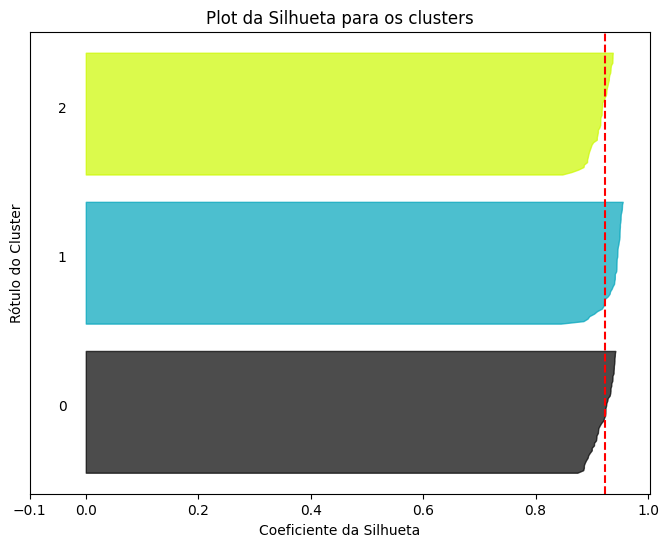

In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm

# Calcular o score da silhueta para cada amostra
silhouette_per_sample = silhouette_samples(X, y_kmeans)

# Calcular o score médio da silhueta
average_silhouette_score = silhouette_score(X, y_kmeans)

print(f"O score médio da silhueta é: {average_silhouette_score}")

# Plotar o gráfico da silhueta
fig, ax1 = plt.subplots(1, 1)
fig.set_size_inches(8, 6)

y_lower = 10
for i in range(3): # Considerando 3 clusters
    # Agrupar os scores da silhueta para o cluster i e classificá-los
    ith_cluster_silhouette_values = silhouette_per_sample[y_kmeans == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 3)
    ax1.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_silhouette_values,
                      facecolor=color, edgecolor=color, alpha=0.7)

    # Rotular os plots da silhueta com seus números de cluster no meio
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    # Calcular o novo y_lower para o próximo plot
    y_lower = y_upper + 10 # 10 para espaço entre os clusters

ax1.set_title("Plot da Silhueta para os clusters")
ax1.set_xlabel("Coeficiente da Silhueta")
ax1.set_ylabel("Rótulo do Cluster")

# Linha vertical para o score médio da silhueta
ax1.axvline(x=average_silhouette_score, color="red", linestyle="--")

ax1.set_yticks([])  # Limpar os ticks do eixo y
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

plt.show()

Através do gráfico, podemos analisar rapidamente os tamanhos dos agrupamentos gerados e identificar se esses grupos contém outliers. No gráfico acima, especificamente, **os coeficientes estão bem distantes do 0**, o que é um indicador de um bom agrupamento.

## Atividade

Analise o conjunto de dados abaixo. Encontre o número de k com o método do cotovelo e depois utilize o método da silhueta para dizer se os grupos ficaram bons.

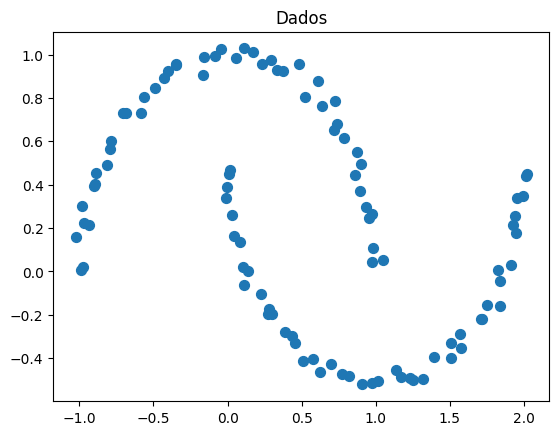

In [ ]:
from sklearn.datasets import make_moons

X, y_real = make_moons(noise=0.03, random_state=0)
plt.scatter(X[:,0], X[:,1], s=50)
plt.title('Dados')
plt.show()

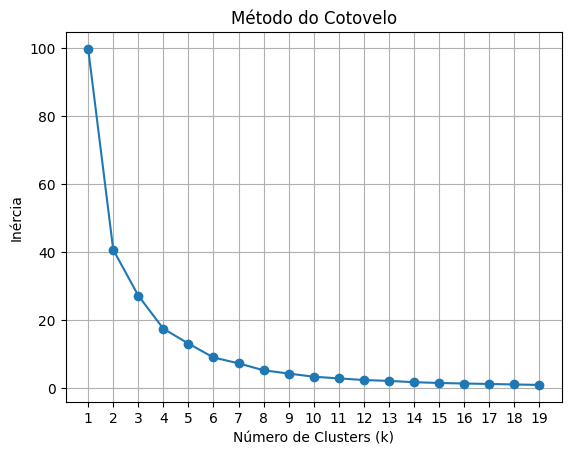

In [ ]:
## Aplique o método do cotovelo para definir um k
inercia = []
for i in range(1, 20):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10) # Adicionado n_init para evitar warning
    kmeans.fit(X)
    inercia.append(kmeans.inertia_)

plt.plot(range(1, 20), inercia, marker='o') # Adicionado o marcador 'o'
plt.title('Método do Cotovelo')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia')
plt.xticks(range(1, 20)) # Adicionado para mostrar todos os valores de k no eixo x
plt.grid(True) # Adicionado grade para melhor visualização
plt.show()

In [ ]:
## Treine o k-médias com o k escolhido
kmeans = KMeans(n_clusters=9, random_state=42)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

O score médio da silhueta é: 0.5235593556722399


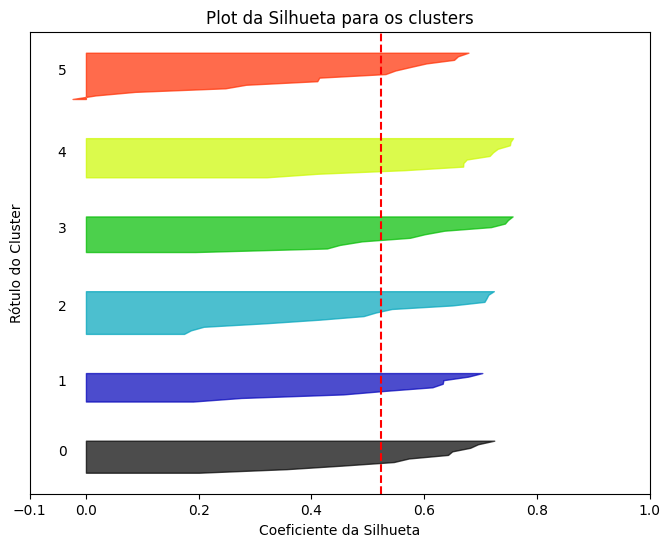

In [ ]:
## Avalie com o método de silhueta
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm

# Calcular o score da silhueta para cada amostra
silhouette_per_sample = silhouette_samples(X, y_kmeans)

# Calcular o score médio da silhueta
average_silhouette_score = silhouette_score(X, y_kmeans)

print(f"O score médio da silhueta é: {average_silhouette_score}")

# Plotar o gráfico da silhueta
fig, ax1 = plt.subplots(1, 1)
fig.set_size_inches(8, 6)

y_lower = 10
for i in range(6): # Considerando 6 clusters
    # Agrupar os scores da silhueta para o cluster i e classificá-los
    ith_cluster_silhouette_values = silhouette_per_sample[y_kmeans == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 6)
    ax1.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_silhouette_values,
                      facecolor=color, edgecolor=color, alpha=0.7)

    # Rotular os plots da silhueta com seus números de cluster no meio
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

    # Calcular o novo y_lower para o próximo plot
    y_lower = y_upper + 10 # 10 para espaço entre os clusters

ax1.set_title("Plot da Silhueta para os clusters")
ax1.set_xlabel("Coeficiente da Silhueta")
ax1.set_ylabel("Rótulo do Cluster")

# Linha vertical para o score médio da silhueta
ax1.axvline(x=average_silhouette_score, color="red", linestyle="--")

ax1.set_yticks([])  # Limpar os ticks do eixo y
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

plt.show()

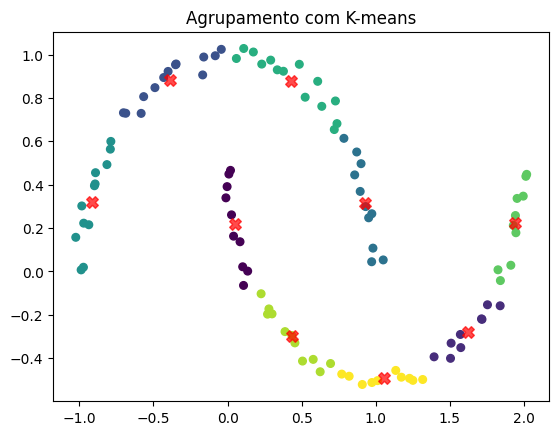

In [ ]:
y_kmeans = kmeans.predict(X)

# Visualizando os grupos encontrados
plt.scatter(X[:,0], X[:,1], c=y_kmeans, s=30, cmap='viridis')
centros = kmeans.cluster_centers_
plt.scatter(centros[:,0], centros[:,1], c='red', s=70, alpha=0.7, marker='X')
plt.title('Agrupamento com K-means')
plt.show()